In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset

In [2]:
class ModuloDataset(Dataset):
    def __init__(self, data):
        self.inputs = data[:,:3]
        self.labels = data[:,3:].squeeze(dim=1)

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.labels[index]

In [3]:
### Create dataset
modulo_number = 113
data = []

for i in range(modulo_number):
    for j in range(modulo_number):
        data.append([i, j, modulo_number, (i + j) % modulo_number])

data = torch.tensor(data)

In [4]:
train_perecentage = 0.3

shuffled_data = data[torch.randperm(data.shape[0])]
train_idx = int(train_perecentage * shuffled_data.shape[0])
train_split = shuffled_data[:train_idx]
test_split = shuffled_data[train_idx:]
print(train_split.shape[0], test_split.shape[0])

train_dataset = ModuloDataset(train_split)
test_dataset = ModuloDataset(test_split)

3830 8939


In [5]:
from torch.nn import Embedding, MultiheadAttention, Linear, Module, ReLU

class MLP(Module):
    def __init__(self, d_model, d_hidden):
        super().__init__()
        self.up_projection = Linear(d_model, d_hidden)
        self.down_projection = Linear(d_hidden, d_model)
        self.relu = ReLU()

    def forward(self, x):
        h1 = self.up_projection(x)
        r1 = self.relu(h1)
        out = self.down_projection(r1)
        return out

class ModuloTransformer(Module):
    def __init__(self, modulo_number, d_embed, n_heads, d_ff):
        super().__init__()
        self.embed = Embedding(modulo_number + 1, d_embed)      # +1 because of the '=' token
        self.pos_embed = Embedding(3, d_embed)      # hard code to 3 bc seq len is always that
        self.mh_attn = MultiheadAttention(d_embed, n_heads, batch_first=True)     # not masked attention, batch is first dim
        self.mlp = MLP(d_embed, d_ff)
        self.unembed = Linear(d_embed, modulo_number)

    def forward(self, x):
        x_embed = self.embed(x)
        pos_embed = self.pos_embed(torch.arange(3, device=x.device))
        x_embed += pos_embed
        x_attn, _ = self.mh_attn(x_embed, x_embed, x_embed)
        x_attn += x_embed               # residual
        x_ff = x_attn + self.mlp(x_attn) # residual
        logits = self.unembed(x_ff)
        # complicated indexing so that it works if there is a batch dim or not
        return logits[..., 2, :]
    
    def predict(self, x):
        logits = self.forward(x)
        probs = torch.softmax(logits, dim=-1)
        # complicated indexing so that it works if there is a batch dim or not
        prediction = torch.argmax(probs, dim=-1) # 2 because we only predict from the last output
        return prediction

In [6]:
len(train_dataset), len(test_dataset)

(3830, 8939)

In [ ]:
### TRAINING LOOP
from torch.utils.data import DataLoader
from torch.optim import AdamW
import time

# hypers come from paper
BATCH_SIZE = len(train_dataset)
LR = 0.001
GAMMA = 1
EPOCHS = 40_000
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"

model = ModuloTransformer(modulo_number, 128, 4, 512).to(DEVICE)
optimizer = AdamW(model.parameters(), LR, weight_decay=GAMMA)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

def calculate_accuracy(logits,  y):
    # logits will have shape B x M where B is batch size and M is the modulo number
    # y will have shape B
    preds = torch.argmax(logits, dim=-1)
    bools = preds == y
    return bools.float().mean()

log_filename = f"log_{int(time.time())}"
log_file = open(log_filename, "x")
log_file.write(f"Config:\n{BATCH_SIZE=}\n{LR=}\n{GAMMA=}\n{EPOCHS=}\n{DEVICE=}\n{modulo_number=}\n\n")

train_losses = []
test_losses = []
train_accs = []
test_accs = []
for epoch in range(EPOCHS):
    for x_train, y_train in train_loader:
        x_train, y_train = x_train.to(DEVICE), y_train.to(DEVICE)
        logits = model(x_train)
        train_acc = calculate_accuracy(logits, y_train)
        loss = nn.functional.cross_entropy(logits, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # check performance on test data
        with torch.no_grad():
            x_test, y_test = next(iter(test_loader))
            x_test, y_test = x_test.to(DEVICE), y_test.to(DEVICE)
            logits = model(x_test)
            test_acc = calculate_accuracy(logits, y_test)
            test_loss = nn.functional.cross_entropy(logits, y_test)

        train_losses.append(loss.item())
        test_losses.append(test_loss.item())
        train_accs.append(train_acc)
        test_accs.append(test_acc)
    if epoch % 100 == 0:
        s = f"Epoch {epoch}: Loss -- Train: {loss.item():.4f} Test: {test_loss.item():.4f}    Accuracy -- Train: {train_acc:.4f} Test: {test_acc:.4f}"
        log_file.write(s + '\n')
        if epoch % 1000 == 0:
            print(s)

log_file.close()

Epoch 0: Loss -- Train: 4.9942 Test: 4.8478    Accuracy -- Train: 0.0076 Test: 0.0091


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x106bed4f0>>
Traceback (most recent call last):
  File "/Users/pjhenwood/VS Projects/CS520/Final Project/Grokking/.venv/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


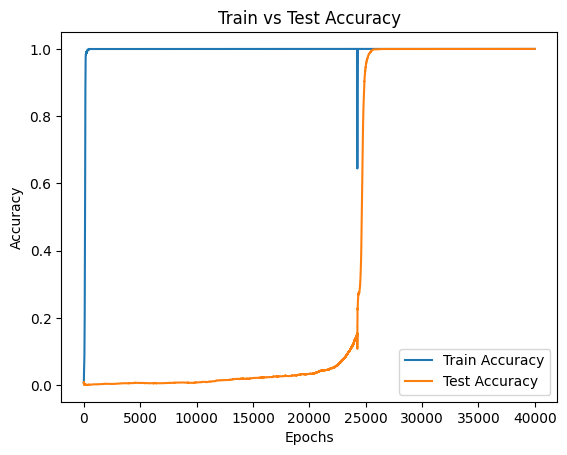

In [ ]:
# Should probably add better logging and graphing stuff now so that we can track progress
import matplotlib.pyplot as plt

train_accs_np = [acc.cpu().item() for acc in train_accs]
test_accs_np = [acc.cpu().item() for acc in test_accs]

epochs = range(1, len(train_accs_np) + 1)

plt.plot(epochs, train_accs_np, label='Train Accuracy')
plt.plot(epochs, test_accs_np, label='Test Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy')
plt.legend()


plt.savefig("accuracy.png")

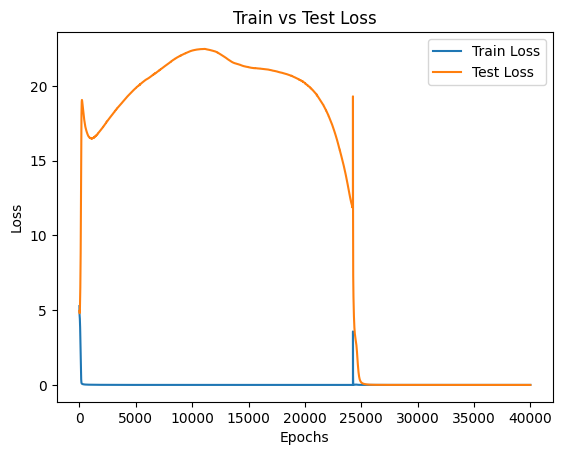

In [ ]:
# Should probably add better logging and graphing stuff now so that we can track progress
import matplotlib.pyplot as plt

epochs = range(1, len(train_accs_np) + 1)

plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, test_losses, label='Test Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train vs Test Loss')
plt.legend()


plt.savefig("loss.png")